# Entrenamiento y evaluación de modelos — Modelo de riesgo crediticio
## PIM5 · Avance 2 (V1.1.0 y V1.1.1) · `ft_engineering.py` y `model_training_evaluation.py`

---

## Índice

1. [Introducción y objetivos del avance](#1)
2. [Importación de librerías](#2)
3. [Carga de datos y verificación](#3)
4. [Ingeniería de características (`ft_engineering.py`)](#4)
5. [Función de evaluación y métricas de la clase "no pagó"](#5)
6. [Modelos candidatos](#6)
7. [Entrenamiento y evaluación en train y test](#7)
8. [Sobreajuste: train frente a test](#8)
9. [Sensibilidad a los hiperparámetros](#9)
10. [Validación cruzada estratificada](#10)
11. [Métricas en datos desbalanceados: curvas ROC y Precision-Recall](#11)
12. [Efecto de `puntaje` (fuga de información)](#12)
13. [Comparación exhaustiva de modelos](#13)
14. [Selección del modelo final y del umbral de decisión](#14)
15. [Control con partición temporal](#15)
16. [Variables que explican el riesgo](#16)
17. [Guardado y verificación del modelo](#17)
18. [Conclusiones, limitaciones y próximos pasos](#18)

---

<a id="1"></a>
## 1. Introducción y objetivos del avance

En el **Avance 1** se hizo el EDA y se tomaron las decisiones de preparación de datos (sección 11.3 de `comprension_eda.ipynb`). Este avance las implementa y entrena los primeros modelos para anticipar si un solicitante **pagará a tiempo** (`Pago_atiempo`: 1 = pagó, 0 = no pagó).

**Objetivos:**
- Construir `ft_engineering.py`: limpieza por reglas, imputación, codificación y escalado dentro de un *pipeline* que se ajusta solo con datos de entrenamiento.
- Entrenar y comparar varios modelos (regresión logística, árbol de decisión, Random Forest, XGBoost y LightGBM) contra un modelo de referencia que no aprende nada.
- Evaluarlos con métricas apropiadas para una clase minoritaria (ROC-AUC, PR-AUC, Precision, Recall y F1 de la clase "no pagó") y con validación cruzada estratificada.
- Documentar el efecto de `puntaje` (fuga de información) y entrenar el modelo de producción **sin** esa variable.
- Elegir el mejor modelo, definir su umbral de decisión y guardarlo para la API del Avance 4.

**Contexto que condiciona todo el avance:** la base es sintética y de baja calidad (aclarado por la cátedra) y solo hay 511 créditos no pagados. Las métricas pueden resultar bajas; se **documentan, no se fuerzan**. Lo que se evalúa en el módulo es la puesta en producción completa, no el rendimiento del modelo.

**Decisión de alcance:** la lógica vive en los dos archivos `.py` (que son los que usarán la API y el monitoreo) y este notebook los **importa** y presenta los resultados. No se duplica código entre el notebook y los módulos.

<a id="2"></a>
## 2. Importación de librerías

In [1]:
# ===== MANIPULACIÓN DE DATOS =====
import pandas as pd
import numpy as np

# ===== VISUALIZACIÓN =====
import matplotlib.pyplot as plt
import seaborn as sns

# ===== MÉTRICAS Y VALIDACIÓN =====
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from lightgbm import LGBMClassifier

# ===== MÓDULOS DEL PROYECTO (mlops_pipeline/src) =====
from cargar_datos import cargarDatos
from ft_engineering import (
    SEMILLA, TARGET, columnas_entrada, crear_pipeline_features, dividir_datos,
    ft_engineering, limpiar_datos,
)
from model_training_evaluation import (
    calcular_metricas, comparar_modelos, construir_pipeline, crear_modelos, elegir_modelo,
    graficar_comparacion, guardar_modelo, proba_no_pago, umbral_optimo_f1, validacion_cruzada,
)

# ===== UTILIDADES =====
import warnings
warnings.filterwarnings('ignore')

# --- Reproducibilidad: la semilla 42 se define una sola vez, en ft_engineering.py ---
np.random.seed(SEMILLA)

# --- Configuración general de gráficos y tablas ---
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Colores consistentes con el EDA
COLOR_PAGO = '#2E86AB'      # 1 = pagó a tiempo
COLOR_NO_PAGO = '#E63946'   # 0 = no pagó a tiempo

print('Librerías y módulos importados correctamente.')
print(f'Semilla: {SEMILLA} | Variable objetivo: {TARGET}')

Librerías y módulos importados correctamente.
Semilla: 42 | Variable objetivo: Pago_atiempo


<a id="3"></a>
## 3. Carga de datos y verificación

Los datos se cargan con la función del Avance 1 (`cargar_datos.py`). Antes de usarlos se verifica que la base sea la misma del EDA: nunca se asume que un archivo está bien solo porque "ya se revisó antes".

In [2]:
df = cargarDatos()

print('VERIFICACIÓN DE LA BASE')
print('=' * 70)
print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Período: {df["fecha_prestamo"].min():%d/%m/%Y} a {df["fecha_prestamo"].max():%d/%m/%Y}')
print(f'Filas duplicadas: {df.duplicated().sum()}')
print('\nDistribución de la variable objetivo:')
resumen = df[TARGET].value_counts().rename({1: 'Pagó a tiempo (1)', 0: 'No pagó (0)'}).to_frame('créditos')
resumen['%'] = (resumen['créditos'] / len(df) * 100).round(2)
display(resumen)

VERIFICACIÓN DE LA BASE
Dimensiones: 10,763 filas x 23 columnas
Período: 26/11/2024 a 26/04/2026
Filas duplicadas: 0

Distribución de la variable objetivo:


,créditos,%
Pago_atiempo,,
Pagó a tiempo (1),10252,95.2500
No pagó (0),511,4.7500


**Verificación:** 10.763 créditos, 23 columnas, sin duplicados, 95,25 % pagó a tiempo y 4,75 % no (511 créditos). Coincide con el EDA del Avance 1: se puede continuar.

<a id="4"></a>
## 4. Ingeniería de características (`ft_engineering.py`)

El módulo hace tres cosas, en este orden:

1. **Limpieza por reglas fijas** (`limpiar_datos`): corrige valores imposibles o inválidos detectados en el EDA. Son reglas que no aprenden de los datos, por eso no generan fuga de información.
2. **Preprocesador** (`crear_preprocesador`): imputa nulos, agrega indicadores de "dato faltante", transforma montos con logaritmo, escala y codifica categorías. **Esto sí aprende de los datos** (medianas, desvíos, categorías), por lo que se ajusta *solo con entrenamiento*.
3. **Partición** (`dividir_datos`): estratificada por `Pago_atiempo` con semilla 42.

*Alternativa profesional aplicada:* en lugar de transformar la base una vez y guardar el resultado, el preprocesamiento queda **dentro de un `Pipeline` de scikit-learn** junto al modelo. Así (a) se reajusta solo con las filas de entrenamiento en cada fold de la validación cruzada, y (b) la API de producción recibe los datos crudos y aplica exactamente las mismas transformaciones.

### 4.1 Reglas de limpieza

Se compara la base antes y después de `limpiar_datos`:

In [3]:
limpio = limpiar_datos(df)

cambios = pd.DataFrame([
    ('tendencia_ingresos', 'valores fuera de Creciente/Decreciente/Estable -> nulo',
     (df['tendencia_ingresos'].notna() & ~df['tendencia_ingresos'].isin(['Creciente', 'Decreciente', 'Estable'])).sum()),
    ('edad_cliente', 'edades > 90 (centinela 121-123) -> nulo',
     (df['edad_cliente'] > 90).sum()),
    ('puntaje_datacredito', 'valores <= 0 (código de "sin dato") -> nulo',
     (df['puntaje_datacredito'] <= 0).sum()),
    ('tipo_credito', 'códigos fuera de 4, 9, 10 y 6 (hoy 7 y 68) -> "Otros"',
     (~df['tipo_credito'].isin([4, 9, 10, 6])).sum()),
], columns=['variable', 'regla', 'registros_afectados'])
display(cambios)

print('\nNulos antes y después de la limpieza (solo columnas que cambian):')
comparacion_nulos = pd.DataFrame({
    'antes': df[['tendencia_ingresos', 'edad_cliente', 'puntaje_datacredito']].isnull().sum(),
    'después': limpio[['tendencia_ingresos', 'edad_cliente', 'puntaje_datacredito']].isnull().sum(),
})
display(comparacion_nulos)

print('\ntipo_credito después de la limpieza:')
display(limpio['tipo_credito'].value_counts().to_frame('créditos'))
print(f'\nEl DataFrame original no se modificó: edad máxima = {df["edad_cliente"].max()}')

,variable,regla,registros_afectados
0,tendencia_ingresos,valores fuera de Creciente/Decreciente/Estable...,58
1,edad_cliente,edades > 90 (centinela 121-123) -> nulo,150
2,puntaje_datacredito,"valores <= 0 (código de ""sin dato"") -> nulo",146
3,tipo_credito,"códigos fuera de 4, 9, 10 y 6 (hoy 7 y 68) -> ...",3



Nulos antes y después de la limpieza (solo columnas que cambian):


,antes,después
tendencia_ingresos,2932,2990
edad_cliente,0,150
puntaje_datacredito,6,152



tipo_credito después de la limpieza:


,créditos
tipo_credito,
4,7747
9,2876
10,116
6,21
Otros,3



El DataFrame original no se modificó: edad máxima = 123


**Lectura.** Las reglas afectan 58, 150, 146 y 3 registros. La mayor parte corresponde al valor centinela de la edad y al código de "sin dato" del puntaje externo. Tras la limpieza:

- `tendencia_ingresos` queda con **2.990 nulos** (27,78 %): los 2.932 originales más los 58 valores numéricos inválidos, igual que en el EDA.
- `edad_cliente` queda con 150 nulos (las edades 121-123) y `puntaje_datacredito` con 152 (146 inválidos más 6 originales).
- `tipo_credito` conserva los códigos 4, 9, 10 y 6. Los 3 registros restantes (dos del código 7 y uno del 68) pasan a **"Otros"**. Cualquier código nuevo que llegue en producción también cae en "Otros", por lo que la API no se rompe ante un producto desconocido.

Los nulos **no se imputan acá**: la imputación depende de los datos de entrenamiento y la hace el preprocesador (sección 4.3). La limpieza trabaja sobre una copia: el DataFrame original conserva la edad máxima de 123.

### 4.2 Partición entrenamiento / prueba

Partición **estratificada** 80/20 con semilla 42: ambos conjuntos conservan la proporción 95/5. Con solo 511 créditos no pagados, una partición no estratificada podría dejar una cantidad muy distinta de casos de interés en cada conjunto.

In [4]:
datos = ft_engineering(df, con_puntaje=False)
X_train, X_test = datos['X_train'], datos['X_test']
y_train, y_test = datos['y_train'], datos['y_test']

particion = pd.DataFrame({
    'créditos': [len(y_train), len(y_test)],
    'no pagaron': [(y_train == 0).sum(), (y_test == 0).sum()],
    '% no pagaron': [(y_train == 0).mean() * 100, (y_test == 0).mean() * 100],
}, index=['Entrenamiento (80 %)', 'Prueba (20 %)'])
display(particion)

print(f'Columnas de entrada del modelo ({X_train.shape[1]}): {X_train.columns.tolist()}')
print('`puntaje` y `fecha_prestamo` NO están entre las entradas:', 'puntaje' not in X_train.columns and 'fecha_prestamo' not in X_train.columns)

,créditos,no pagaron,% no pagaron
Entrenamiento (80 %),8610,409,4.7503
Prueba (20 %),2153,102,4.7376


Columnas de entrada del modelo (20): ['capital_prestado', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'saldo_mora', 'saldo_total', 'saldo_principal', 'saldo_mora_codeudor', 'promedio_ingresos_datacredito', 'plazo_meses', 'edad_cliente', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'tipo_credito', 'tipo_laboral', 'tendencia_ingresos']
`puntaje` y `fecha_prestamo` NO están entre las entradas: True


**Lectura.** Entrenamiento: 8.610 créditos con 409 no pagos (4,75 %). Prueba: 2.153 créditos con 102 no pagos (4,74 %). La estratificación mantuvo la proporción en ambos conjuntos.

El conjunto de prueba tiene **solo 102 casos de interés**: detectar un no pago de más o de menos mueve el Recall casi un punto porcentual (1/102 ≈ 1 %). Las métricas de test son, por lo tanto, ruidosas. Por eso se complementan con validación cruzada (sección 10) y con intervalos de confianza bootstrap (sección 14).

Las entradas del modelo no incluyen `puntaje` (fuga de información) ni `fecha_prestamo` (se usa solo para la partición temporal y, en el Avance 3, para el monitoreo).

### 4.3 Preprocesador: ajuste solo con entrenamiento

Se ajusta el *pipeline* de características con `X_train` y se aplica a ambos conjuntos. Hay dos versiones:

- **`pipeline_arbol`** (Árbol, Random Forest, XGBoost, LightGBM): imputa y codifica, sin escalar. Los modelos de árboles no se ven afectados por la escala ni por la asimetría de las variables.
- **`pipeline_lineal`** (regresión logística): además aplica `log(1 + x)` a los montos, estandariza y descarta `saldo_principal` (Spearman 0,95 con `saldo_total`).

In [5]:
pipe_arbol = datos['pipeline_arbol'].fit(X_train)       # se ajusta SOLO con train
pipe_lineal = datos['pipeline_lineal'].fit(X_train)

Xa_train, Xa_test = pipe_arbol.transform(X_train), pipe_arbol.transform(X_test)
Xl_train = pipe_lineal.transform(X_train)

print('RESULTADO DEL PREPROCESADO')
print('=' * 70)
print(f'Pipeline de árboles : train {Xa_train.shape} | test {Xa_test.shape}')
print(f'Pipeline lineal     : train {Xl_train.shape} (una columna menos de montos y de indicadores)')
print(f'Nulos restantes (train / test): {Xa_train.isnull().sum().sum()} / {Xa_test.isnull().sum().sum()}')

indicadores = [c for c in Xa_train.columns if c.startswith('missingindicator_')]
dummies = [c for c in Xa_train.columns if c.startswith(('tipo_credito_', 'tipo_laboral_', 'tendencia_ingresos_'))]
print(f'\nIndicadores de dato faltante ({len(indicadores)}): {indicadores}')
print(f'Variables One-Hot ({len(dummies)}): {dummies}')

# Prueba de que las medianas salen de train y no de toda la base
imputador = pipe_arbol['preprocesador'].named_transformers_['montos']['imputar']
columnas_montos = pipe_arbol['preprocesador'].transformers_[0][2]
mediana_train = dict(zip(columnas_montos, imputador.statistics_))['saldo_total']
print(f'\nMediana de saldo_total usada para imputar (train): {mediana_train:,.0f} | en toda la base: {df["saldo_total"].median():,.0f}')

RESULTADO DEL PREPROCESADO
Pipeline de árboles : train (8610, 35) | test (2153, 35)
Pipeline lineal     : train (8610, 33) (una columna menos de montos y de indicadores)
Nulos restantes (train / test): 0 / 0

Indicadores de dato faltante (7): ['missingindicator_saldo_mora', 'missingindicator_saldo_total', 'missingindicator_saldo_principal', 'missingindicator_saldo_mora_codeudor', 'missingindicator_promedio_ingresos_datacredito', 'missingindicator_edad_cliente', 'missingindicator_puntaje_datacredito']
Variables One-Hot (11): ['tipo_credito_10', 'tipo_credito_4', 'tipo_credito_6', 'tipo_credito_9', 'tipo_credito_Otros', 'tipo_laboral_Empleado', 'tipo_laboral_Independiente', 'tendencia_ingresos_Creciente', 'tendencia_ingresos_Decreciente', 'tendencia_ingresos_Estable', 'tendencia_ingresos_Sin dato']

Mediana de saldo_total usada para imputar (train): 15,856 | en toda la base: 16,178


**Lectura.**

- El pipeline de árboles entrega **35 características sin nulos**: 24 numéricas (17 variables más 7 indicadores de dato faltante) y 11 variables One-Hot. El pipeline lineal entrega 33, porque descarta `saldo_principal` y su indicador (redundante con `saldo_total`).
- Los 7 indicadores corresponden a las variables que tienen nulos en entrenamiento. La ausencia de ingresos queda representada por la categoría "Sin dato" de `tendencia_ingresos` y por el indicador de `promedio_ingresos_datacredito`, como se decidió en el EDA (sección 11.3).
- Las medianas de imputación se calculan solo con train: la mediana de `saldo_total` es 15.856 en entrenamiento y 16.178 en toda la base. Esa diferencia, pequeña pero real, confirma que el ajuste no usó los datos de prueba.
- `handle_unknown='ignore'` en el One-Hot hace que una categoría nueva en producción no genere error: se codifica con ceros.

<a id="5"></a>
## 5. Función de evaluación y métricas de la clase "no pagó"

Todos los modelos se evalúan con la misma función (`calcular_metricas`, en `model_training_evaluation.py`). Evita repetir código y olvidar una métrica en algún modelo.

**La clase de interés es la 0 ("no pagó")**, que es la minoritaria. Precision, Recall y F1 se calculan sobre esa clase, y ROC-AUC y PR-AUC con la **probabilidad de no pago**:

- **Recall** de "no pagó": de los créditos que no se pagaron, qué porcentaje detecta el modelo.
- **Precision** de "no pagó": de los créditos que el modelo marca como riesgosos, qué porcentaje realmente no se pagó.
- **F1**: promedio armónico de ambos.
- **ROC-AUC**: probabilidad de que un crédito no pagado reciba mayor riesgo que uno pagado (0,5 = azar, 1 = perfecto).
- **PR-AUC**: resume la curva Precision-Recall; su valor de azar es la proporción de la clase de interés (0,0475), no 0,5.
- **Accuracy**: solo como referencia (ver abajo).

*Alternativa profesional:* en un proyecto de producción estas métricas se registran por corrida en una herramienta de seguimiento de experimentos (por ejemplo MLflow). Acá se concentran en una función y una tabla.

In [6]:
# Demostración de por qué la exactitud (accuracy) no sirve en esta base:
# un "modelo" que siempre predice "pagó a tiempo" no detecta ni un solo caso de riesgo.
siempre_paga = np.zeros(len(y_test))          # probabilidad de no pago = 0 para todos
m = calcular_metricas(y_test, siempre_paga)
print('MODELO QUE SIEMPRE PREDICE "PAGÓ A TIEMPO"')
print('=' * 70)
print(f'Accuracy : {m["accuracy"]:.4f}   <- parece excelente')
print(f'Recall   : {m["recall"]:.4f}   <- no detecta ningún no pago')
print(f'F1       : {m["f1"]:.4f}')

MODELO QUE SIEMPRE PREDICE "PAGÓ A TIEMPO"
Accuracy : 0.9526   <- parece excelente
Recall   : 0.0000   <- no detecta ningún no pago
F1       : 0.0000


**Lectura:** el modelo trivial tiene 95,3 % de *accuracy* y detecta 0 de los 102 créditos no pagados del conjunto de prueba. Por eso la *accuracy* no se usa para comparar: se informa solo como referencia.

<a id="6"></a>
## 6. Modelos candidatos

Se comparan cinco modelos de complejidad creciente y un modelo de **referencia** (`DummyClassifier`) que siempre asigna la probabilidad de la clase mayoritaria: sirve como piso (ROC-AUC = 0,5). Un modelo que no lo supera no aporta nada.

| Modelo | Por qué se incluye | Pipeline |
|---|---|---|
| Referencia (prior) | Piso de comparación | Árboles |
| Regresión Logística | Modelo lineal interpretable; punto de partida habitual | Lineal (log + escalado) |
| Árbol de Decisión | Reglas simples y legibles; propenso a sobreajustar | Árboles |
| Random Forest | Ensamble de árboles independientes (*bagging*) | Árboles |
| XGBoost | *Boosting* de árboles; estándar en datos tabulares | Árboles |
| LightGBM | *Boosting* más rápido; crece hoja por hoja | Árboles |

**Tratamiento del desbalanceo (95/5):** se pondera la clase minoritaria en el entrenamiento (`class_weight='balanced'`; en XGBoost, `scale_pos_weight` calculado con `y_train`). Sin esto, los modelos aprenden a predecir siempre "pagó". No se usa remuestreo (SMOTE): con una señal tan débil, generar casos sintéticos sobre una base ya sintética sumaría ruido.

**Hiperparámetros conservadores:** árboles poco profundos, hojas con muchas filas y regularización. Con ~400 casos de "no pagó" en entrenamiento, los modelos flexibles memorizan el train (sección 8). La sección 9 muestra que probar configuraciones distintas no cambia el resultado más allá del ruido.

In [7]:
modelos = crear_modelos(y_train)
descripcion = pd.DataFrame({
    'clasificador': [type(clf).__name__ for clf, _ in modelos.values()],
    'pipeline': ['lineal' if escalar else 'árboles' for _, escalar in modelos.values()],
}, index=modelos.keys())
display(descripcion)

print('scale_pos_weight de XGBoost (n_no_pagan / n_pagan en train):',
      round(modelos['XGBoost'][0].get_params()['scale_pos_weight'], 4))

,clasificador,pipeline
Referencia (prior),DummyClassifier,árboles
Regresión Logística,LogisticRegression,lineal
Árbol de Decisión,DecisionTreeClassifier,árboles
Random Forest,RandomForestClassifier,árboles
XGBoost,XGBClassifier,árboles
LightGBM,LGBMClassifier,árboles


scale_pos_weight de XGBoost (n_no_pagan / n_pagan en train): 0.0499


<a id="7"></a>
## 7. Entrenamiento y evaluación en train y test

Se entrena cada modelo con el conjunto de entrenamiento y se evalúa en ambos conjuntos. El umbral de decisión es **0,5** sobre la probabilidad de no pago (el valor por defecto); en la sección 14 se optimiza para el modelo elegido. Comparar train con test permite detectar sobreajuste.

In [8]:
resultado = comparar_modelos(datos, con_puntaje=False, umbral=0.5)
metricas = resultado['metricas']

columnas_ver = ['modelo', 'conjunto', 'roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'no_pago_predichos', 'tiempo_seg']
print('MÉTRICAS DE LA CLASE "NO PAGÓ" (umbral 0,5)')
print('=' * 70)
display(metricas[columnas_ver].style.format({
    'roc_auc': '{:.4f}', 'pr_auc': '{:.4f}', 'precision': '{:.4f}', 'recall': '{:.4f}',
    'f1': '{:.4f}', 'accuracy': '{:.4f}', 'tiempo_seg': '{:.2f}'}))
print('En test hay 102 créditos no pagados de 2.153.')

MÉTRICAS DE LA CLASE "NO PAGÓ" (umbral 0,5)


,modelo,conjunto,roc_auc,pr_auc,precision,recall,f1,accuracy,no_pago_predichos,tiempo_seg
0,Referencia (prior),train,0.5000,0.0475,0.0000,0.0000,0.0000,0.9525,0,0.52
1,Referencia (prior),test,0.5000,0.0474,0.0000,0.0000,0.0000,0.9526,0,0.52
2,Regresión Logística,train,0.6994,0.1466,0.0858,0.6186,0.1506,0.6686,2950,0.69
3,Regresión Logística,test,0.6931,0.1328,0.0805,0.6078,0.1422,0.6526,770,0.69
4,Árbol de Decisión,train,0.6998,0.1159,0.0794,0.6968,0.1425,0.6016,3591,0.36
5,Árbol de Decisión,test,0.6158,0.0690,0.0640,0.5882,0.1154,0.5727,938,0.36
6,Random Forest,train,0.8079,0.2600,0.1393,0.6479,0.2292,0.7930,1903,2.95
7,Random Forest,test,0.6819,0.1287,0.0898,0.4216,0.1480,0.7701,479,2.95
8,XGBoost,train,0.7956,0.2441,0.1116,0.6748,0.1915,0.7294,2473,1.52
9,XGBoost,test,0.6884,0.1413,0.0886,0.5588,0.1530,0.7069,643,1.52


En test hay 102 créditos no pagados de 2.153.


**Interpretación (test, umbral 0,5).**

- **Todos los modelos superan a la referencia** (ROC-AUC 0,5; PR-AUC 0,047; Recall 0). Hay señal, pero **débil**: el ROC-AUC de los cuatro mejores está entre 0,68 y 0,69, y el árbol de decisión queda atrás (0,62).
- **PR-AUC**: LightGBM 0,159, XGBoost 0,142, Regresión Logística 0,133, Random Forest 0,129 y Árbol 0,069, frente a 0,047 del azar.
- **Precision muy baja (0,06 a 0,09)** a pesar de un Recall de 0,42 a 0,61: con el umbral 0,5 los modelos marcan como riesgosos entre el 22 % y el 44 % de los créditos (por ejemplo, LightGBM marca 677 de 2.153 y detecta 56 de los 102 no pagos). Es la consecuencia esperable de ponderar la clase minoritaria con una señal débil: se detectan más no pagos a costa de muchas falsas alarmas.
- La **accuracy (0,57 a 0,77) es menor que la de la referencia (0,95)** y eso no es un defecto: la referencia acierta porque siempre predice "pagó" y no detecta ningún caso de riesgo.
- Estas diferencias entre modelos (centésimas) son menores que el ruido de un test con 102 casos. No se declara ganador con esta tabla.

<a id="8"></a>
## 8. Sobreajuste: train frente a test

Un modelo que rinde mucho mejor en train que en test está memorizando casos en lugar de aprender patrones. Se mide con la diferencia de ROC-AUC entre ambos conjuntos.

conjunto,test,train,brecha
modelo,,,
Referencia (prior),0.5000,0.5000,0.0000
Regresión Logística,0.6931,0.6994,0.0062
Árbol de Decisión,0.6158,0.6998,0.0839
XGBoost,0.6884,0.7956,0.1072
LightGBM,0.6842,0.8087,0.1245
Random Forest,0.6819,0.8079,0.1260


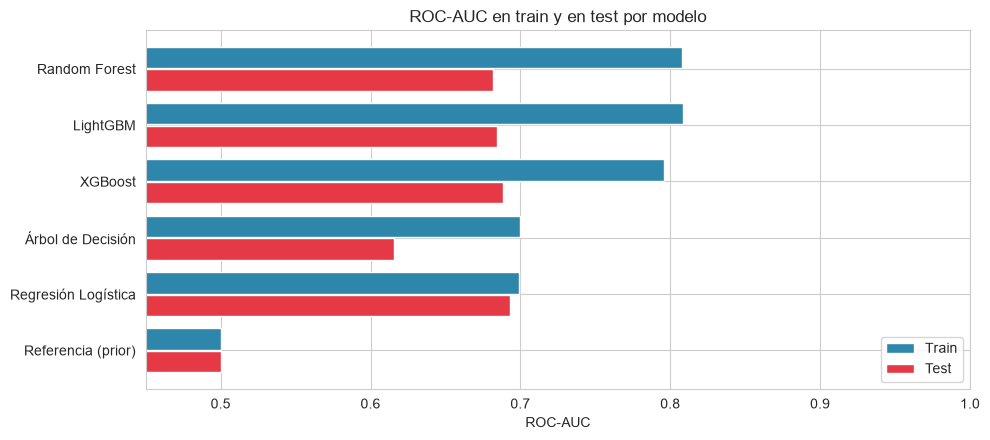

In [9]:
pivote = metricas.pivot(index='modelo', columns='conjunto', values='roc_auc')
pivote['brecha'] = pivote['train'] - pivote['test']
pivote = pivote.sort_values('brecha')
display(pivote)

fig, ax = plt.subplots(figsize=(10, 4.5))
posiciones = np.arange(len(pivote))
ax.barh(posiciones + 0.2, pivote['train'], height=0.38, color=COLOR_PAGO, label='Train')
ax.barh(posiciones - 0.2, pivote['test'], height=0.38, color=COLOR_NO_PAGO, label='Test')
ax.set_yticks(posiciones)
ax.set_yticklabels(pivote.index)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel('ROC-AUC')
ax.set_title('ROC-AUC en train y en test por modelo')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretación.**

- La **regresión logística no sobreajusta** (brecha de 0,006) pero tampoco mejora: es un modelo lineal con poca capacidad.
- Los modelos de ensamble ganan 0,11 a 0,13 de ROC-AUC en train (0,80 a 0,81) y lo pierden en test (0,68 a 0,69): memorizan parte del entrenamiento. El árbol de decisión es el más débil en test (0,62).
- Con los hiperparámetros conservadores adoptados la brecha es moderada. Con una configuración flexible llegaba a 0,25 (LightGBM, sección 9) sin mejorar en test.
- **En test, ningún ensamble supera a la regresión logística en ROC-AUC** (0,693 frente a 0,682-0,688): la complejidad adicional no se traduce en mejor capacidad de discriminar. La señal de la base es débil y parece mayormente lineal o marginal.

<a id="9"></a>
## 9. Sensibilidad a los hiperparámetros

Antes de fijar los hiperparámetros conservadores se probaron cuatro configuraciones de LightGBM, de más a menos flexible, evaluadas con **validación cruzada sobre train**; el test se muestra solo como control y no interviene en la elección. El objetivo no es una búsqueda exhaustiva (Grid Search u Optuna) sino comprobar si la complejidad del modelo mejora algo en esta base.

*Alternativa profesional:* con una señal más fuerte, la búsqueda de hiperparámetros se haría con `GridSearchCV` u Optuna (como en el módulo 4). Acá el tiempo extra no se justifica: la tabla muestra que el rendimiento es insensible al ajuste.

In [10]:
configuraciones = {
    'Flexible (200 árboles, 8 hojas)': dict(n_estimators=200, num_leaves=8, learning_rate=0.05, min_child_samples=30),
    'Intermedia (150 árboles, 6 hojas) <- adoptada': dict(n_estimators=150, num_leaves=6, learning_rate=0.03, min_child_samples=50, reg_lambda=5),
    'Chica (150 árboles, 4 hojas)': dict(n_estimators=150, num_leaves=4, learning_rate=0.03, min_child_samples=60, reg_lambda=5),
    'Muy chica (100 árboles, 3 hojas)': dict(n_estimators=100, num_leaves=3, learning_rate=0.03, min_child_samples=100, reg_lambda=10),
}

filas = []
for nombre, params in configuraciones.items():
    clf = LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight='balanced',
                         verbose=-1, n_jobs=-1, random_state=SEMILLA, **params)
    pipe = construir_pipeline(clf, escalar=False)
    cv = validacion_cruzada(pipe, X_train, y_train)
    pipe.fit(X_train, y_train)
    filas.append({
        'configuración': nombre,
        'ROC-AUC CV': cv['cv_roc_auc_media'], '± ROC': cv['cv_roc_auc_std'],
        'PR-AUC CV': cv['cv_pr_auc_media'], '± PR': cv['cv_pr_auc_std'],
        'ROC-AUC train': calcular_metricas(y_train, proba_no_pago(pipe, X_train))['roc_auc'],
        'ROC-AUC test': calcular_metricas(y_test, proba_no_pago(pipe, X_test))['roc_auc'],
    })
sensibilidad = pd.DataFrame(filas).set_index('configuración')
display(sensibilidad)

,ROC-AUC CV,± ROC,PR-AUC CV,± PR,ROC-AUC train,ROC-AUC test
configuración,,,,,,
"Flexible (200 árboles, 8 hojas)",0.6752,0.0282,0.1591,0.0183,0.9186,0.6735
"Intermedia (150 árboles, 6 hojas) <- adoptada",0.6863,0.0216,0.1515,0.0196,0.8087,0.6842
"Chica (150 árboles, 4 hojas)",0.6824,0.0200,0.1489,0.0173,0.7660,0.6875
"Muy chica (100 árboles, 3 hojas)",0.6722,0.0166,0.1383,0.0165,0.7203,0.6787


**Interpretación.**

- Entre la configuración más flexible y la más simple, el ROC-AUC en validación cruzada varía entre 0,672 y 0,686 y el PR-AUC entre 0,138 y 0,159. Los desvíos entre folds son de 0,017 a 0,028 (ROC) y de 0,017 a 0,020 (PR): **las diferencias entre configuraciones son menores que el desvío**, es decir, indistinguibles del ruido.
- Lo que sí cambia es el sobreajuste: el ROC-AUC en train baja de 0,919 (flexible) a 0,809 (intermedia) y 0,720 (muy chica), mientras el de test se mantiene entre 0,674 y 0,688.
- La configuración flexible tiene el PR-AUC de CV más alto (0,159), pero supera a la adoptada (0,152) por menos de la mitad de un desvío y con un sobreajuste mucho mayor. Se adoptó la **intermedia**: mejor ROC-AUC de CV (0,686) y brecha moderada.
- Una búsqueda sistemática (Grid Search u Optuna) no tendría margen de mejora apreciable en esta base. Queda como alternativa si en el futuro se dispone de datos con más señal.

<a id="10"></a>
## 10. Validación cruzada estratificada

Con solo ~100 no pagos en el conjunto de prueba, una única partición es un resultado ruidoso. La **validación cruzada estratificada de 5 folds** sobre train entrena cada modelo 5 veces y mide su rendimiento en la porción que no vio; la media resume el rendimiento y el desvío indica cuánto varía según qué filas caigan en cada fold. El preprocesador se reajusta dentro de cada fold.

VALIDACIÓN CRUZADA ESTRATIFICADA (5 folds, solo train, umbral 0,5)


,cv_roc_auc_media,cv_roc_auc_std,cv_pr_auc_media,cv_pr_auc_std,cv_precision_media,cv_recall_media,cv_f1_media,cv_f1_std
modelo,,,,,,,,
Referencia (prior),0.5000,0.0000,0.0475,0.0002,0.0000,0.0000,0.0000,0.0000
Regresión Logística,0.6741,0.0275,0.1343,0.0202,0.0798,0.5745,0.1400,0.0108
Árbol de Decisión,0.6391,0.0165,0.0918,0.0150,0.0775,0.5184,0.1346,0.0099
Random Forest,0.6790,0.0257,0.1475,0.0125,0.1004,0.4228,0.1620,0.0261
XGBoost,0.6811,0.0221,0.1419,0.0222,0.0875,0.5158,0.1496,0.0170
LightGBM,0.6863,0.0216,0.1515,0.0196,0.0888,0.5501,0.1528,0.0089


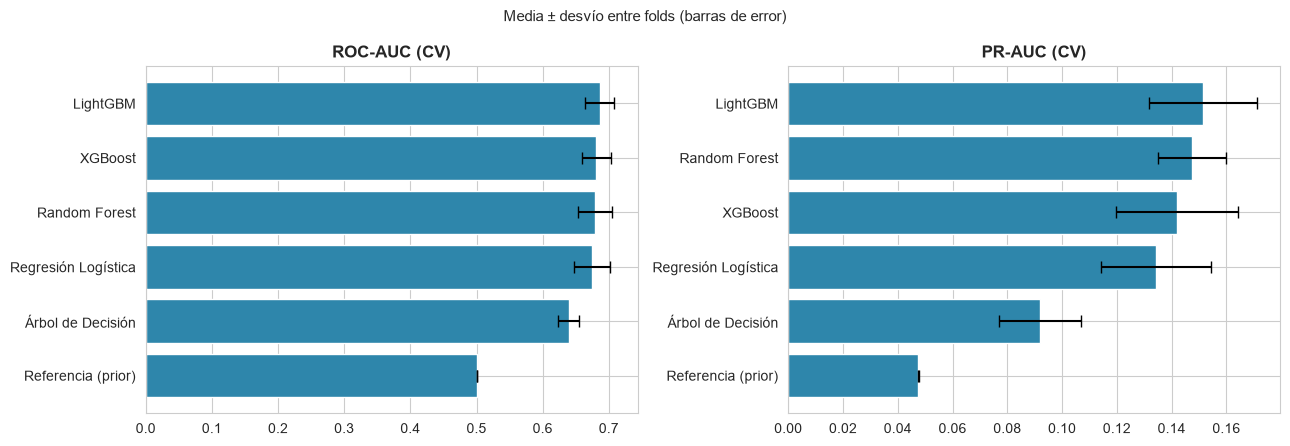

In [11]:
tabla_cv = resultado['cv']
columnas_cv = ['cv_roc_auc_media', 'cv_roc_auc_std', 'cv_pr_auc_media', 'cv_pr_auc_std',
               'cv_precision_media', 'cv_recall_media', 'cv_f1_media', 'cv_f1_std']
print('VALIDACIÓN CRUZADA ESTRATIFICADA (5 folds, solo train, umbral 0,5)')
print('=' * 70)
display(tabla_cv[columnas_cv].style.format('{:.4f}').background_gradient(
    subset=['cv_roc_auc_media', 'cv_pr_auc_media'], cmap='Blues'))

# Gráfico: media y desvío de ROC-AUC y PR-AUC
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, metrica, titulo in zip(ejes, ['roc_auc', 'pr_auc'], ['ROC-AUC (CV)', 'PR-AUC (CV)']):
    datos_graf = tabla_cv[f'cv_{metrica}_media'].sort_values()
    eje.barh(datos_graf.index, datos_graf.values,
             xerr=tabla_cv.loc[datos_graf.index, f'cv_{metrica}_std'], color=COLOR_PAGO, capsize=4)
    eje.set_title(titulo, fontweight='bold')
plt.suptitle('Media ± desvío entre folds (barras de error)', fontsize=11)
plt.tight_layout()
plt.show()

**Interpretación.**

- **Cuatro modelos son estadísticamente indistinguibles**: LightGBM (ROC-AUC 0,686 ± 0,022; PR-AUC 0,152 ± 0,020), XGBoost (0,686 ± 0,016; 0,146 ± 0,019), Random Forest (0,679 ± 0,026; 0,148 ± 0,013) y Regresión Logística (0,674 ± 0,028; 0,134 ± 0,020). Las diferencias entre ellos (0,01 a 0,02) son menores que un desvío.
- El **árbol de decisión es claramente peor** (ROC-AUC 0,639; PR-AUC 0,092) y la **referencia** se queda en el azar (0,500 y 0,0475): confirma que hay señal y que los demás modelos la capturan.
- Los desvíos de 0,02 son una medida honesta de la incertidumbre: con ~400 no pagos en train, el rendimiento cambia según qué casos caigan en cada fold.
- Precision y Recall con el umbral 0,5 son consistentes con el test: Recall de 0,42 a 0,58 y Precision de 0,08 a 0,10 en los cuatro mejores.

<a id="11"></a>
## 11. Métricas en datos desbalanceados: curvas ROC y Precision-Recall

Las curvas muestran el rendimiento en **todos** los umbrales posibles, sin depender del 0,5. La curva Precision-Recall es la más exigente con una clase minoritaria: su línea base (modelo al azar) es la proporción de "no pagó", 4,75 %.

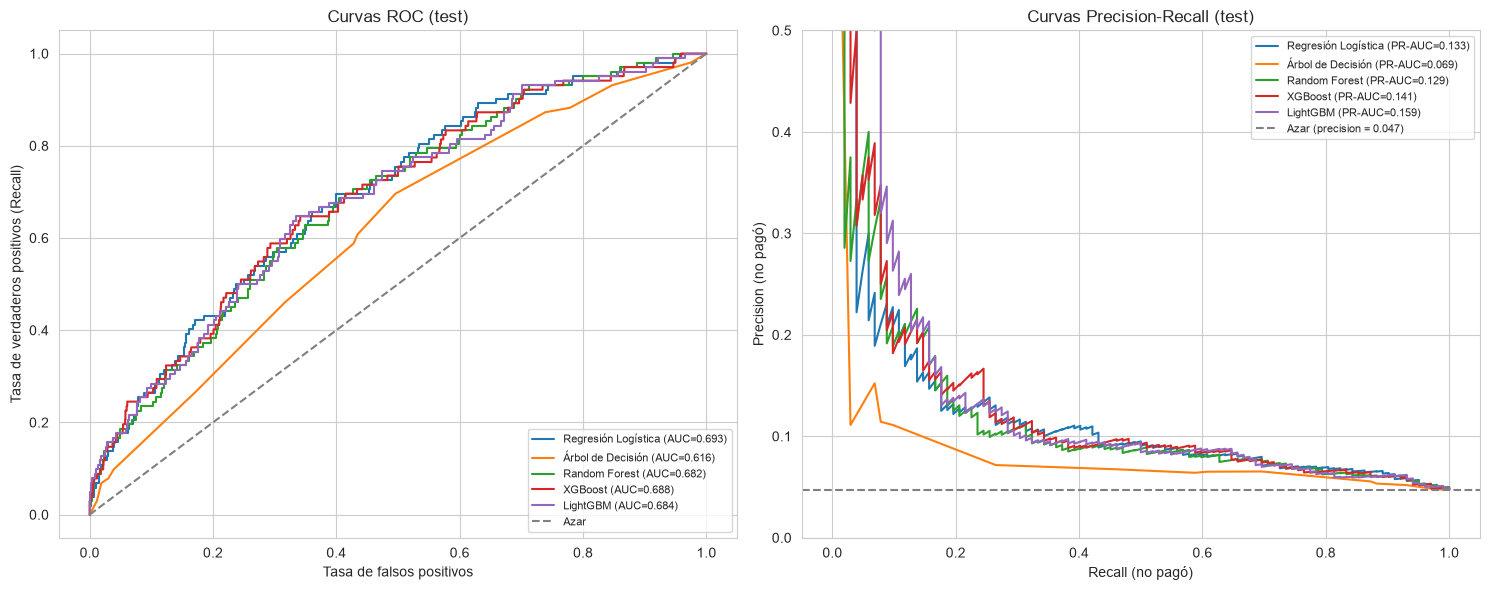

In [12]:
proba_test = resultado['proba_test']
es_no_pago_test = (y_test == 0).astype(int)

fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
for nombre, p in proba_test.items():
    if nombre.startswith('Referencia'):
        continue
    fpr, tpr, _ = roc_curve(es_no_pago_test, p)
    ejes[0].plot(fpr, tpr, label=f'{nombre} (AUC={calcular_metricas(y_test, p)["roc_auc"]:.3f})')
    precision, recall, _ = precision_recall_curve(es_no_pago_test, p)
    ejes[1].plot(recall, precision, label=f'{nombre} (PR-AUC={calcular_metricas(y_test, p)["pr_auc"]:.3f})')

ejes[0].plot([0, 1], [0, 1], '--', color='gray', label='Azar')
ejes[0].set_xlabel('Tasa de falsos positivos')
ejes[0].set_ylabel('Tasa de verdaderos positivos (Recall)')
ejes[0].set_title('Curvas ROC (test)')
ejes[0].legend(fontsize=8, loc='lower right')

azar = es_no_pago_test.mean()
ejes[1].axhline(azar, ls='--', color='gray', label=f'Azar (precision = {azar:.3f})')
ejes[1].set_xlabel('Recall (no pagó)')
ejes[1].set_ylabel('Precision (no pagó)')
ejes[1].set_title('Curvas Precision-Recall (test)')
ejes[1].set_ylim(0, 0.5)
ejes[1].legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

**Interpretación.**

- **Curvas ROC**: las de los cuatro mejores modelos casi se superponen, todas por encima de la diagonal del azar y a una distancia moderada. Con un AUC de 0,68-0,69 el modelo ordena correctamente un par (no pagó, pagó) aproximadamente 7 de cada 10 veces.
- **Curvas Precision-Recall**: todos los modelos quedan por encima de la línea base (0,047). En el tramo de mayor confianza (primer 10 % de los no pagos detectados) la Precision llega a 0,22-0,29 en test, de 4,7 a 6 veces la base; al ampliar el Recall hasta 50 % cae a 0,09-0,10, el doble de la base. Esos valores del tramo inicial se apoyan en pocos casos (10 de 102) y fluctúan mucho.
- Lectura práctica: el modelo sirve para **priorizar** qué solicitudes revisar primero, no para decidir aprobar o rechazar de forma automática.

<a id="12"></a>
## 12. Efecto de `puntaje` (fuga de información)

En el EDA (sección 9) se concluyó que `puntaje` filtra información del desenlace. Aquí se entrenan los mismos modelos **con** esa variable, únicamente para documentar el efecto. **No se usan en producción.**

In [13]:
datos_con = ft_engineering(df, con_puntaje=True)
resultado_con = comparar_modelos(datos_con, con_puntaje=True, con_cv=False)

test_sin = metricas[metricas['conjunto'] == 'test'].set_index('modelo')
test_con = resultado_con['metricas'].query("conjunto == 'test'").set_index('modelo')

efecto = pd.DataFrame({
    'ROC-AUC sin puntaje': test_sin['roc_auc'], 'ROC-AUC con puntaje': test_con['roc_auc'],
    'PR-AUC sin puntaje': test_sin['pr_auc'], 'PR-AUC con puntaje': test_con['pr_auc'],
    'Recall sin puntaje': test_sin['recall'], 'Recall con puntaje': test_con['recall'],
    'F1 sin puntaje': test_sin['f1'], 'F1 con puntaje': test_con['f1'],
})
print('EFECTO DE INCLUIR `puntaje` (test, umbral 0,5)')
print('=' * 70)
display(efecto)

EFECTO DE INCLUIR `puntaje` (test, umbral 0,5)


,ROC-AUC sin puntaje,ROC-AUC con puntaje,PR-AUC sin puntaje,PR-AUC con puntaje,Recall sin puntaje,Recall con puntaje,F1 sin puntaje,F1 con puntaje
modelo,,,,,,,,
Referencia (prior),0.5000,0.5000,0.0474,0.0474,0.0000,0.0000,0.0000,0.0000
Regresión Logística,0.6931,1.0000,0.1328,0.9996,0.6078,1.0000,0.1422,0.9808
Árbol de Decisión,0.6158,1.0000,0.0690,1.0000,0.5882,1.0000,0.1154,1.0000
Random Forest,0.6819,1.0000,0.1287,1.0000,0.4216,1.0000,0.1480,1.0000
XGBoost,0.6884,1.0000,0.1413,1.0000,0.5588,1.0000,0.1530,1.0000
LightGBM,0.6842,1.0000,0.1586,1.0000,0.5490,1.0000,0.1438,1.0000


**Interpretación.**

- Con `puntaje`, **todos los modelos alcanzan ROC-AUC = 1,000** (la regresión logística 1,0000, con PR-AUC 0,9996 y F1 0,981; el resto F1 = 1,000). Sin ella, el ROC-AUC va de 0,62 a 0,69.
- Ese salto no es una mejora del modelo: es la **prueba de la fuga** descrita en el EDA. Hasta un árbol de decisión simple separa los 102 no pagos sin error porque `puntaje` incorpora el desenlace.
- **Decisión:** el modelo de producción se entrena **sin `puntaje`**. Un modelo con métricas perfectas sería inútil para evaluar solicitantes nuevos, porque ese valor no existe en el momento de otorgar el crédito.
- Pendiente: confirmar con el equipo si `puntaje` está disponible al otorgar el crédito. Si lo estuviera, habría que revisar igualmente el valor constante de 95,2278 antes de usarla.

<a id="13"></a>
## 13. Comparación exhaustiva de modelos

Todos los modelos **sin `puntaje`**, sobre el conjunto de prueba. Se ordena por ROC-AUC solo para presentar; la selección (sección 14) se hace con la validación cruzada.

In [14]:
tabla_test = metricas[metricas['conjunto'] == 'test'].set_index('modelo')
columnas_comp = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'no_pago_predichos']

print('COMPARACIÓN DE MODELOS EN TEST (ordenado por ROC-AUC, umbral 0,5)')
print('=' * 70)
display(tabla_test[columnas_comp].sort_values('roc_auc', ascending=False).style.format(
    {c: '{:.4f}' for c in columnas_comp[:-1]}).background_gradient(subset=['roc_auc', 'pr_auc'], cmap='Blues'))

print('\nMEJOR MODELO POR MÉTRICA (sin contar la referencia)')
print('=' * 70)
candidatos = tabla_test.drop(index='Referencia (prior)')
for m in ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1']:
    print(f'{m:10s}: {candidatos[m].idxmax():22s} ({candidatos[m].max():.4f})')

print('\nMEJORA RESPECTO AL AZAR (PR-AUC / proporción de "no pagó" en test)')
print('=' * 70)
azar_pr = tabla_test.loc['Referencia (prior)', 'pr_auc']
for nombre, fila in candidatos.sort_values('pr_auc', ascending=False).iterrows():
    print(f'{nombre:22s}: {fila["pr_auc"] / azar_pr:.1f} veces el azar')

COMPARACIÓN DE MODELOS EN TEST (ordenado por ROC-AUC, umbral 0,5)


,roc_auc,pr_auc,precision,recall,f1,accuracy,no_pago_predichos
modelo,,,,,,,
Regresión Logística,0.6931,0.1328,0.0805,0.6078,0.1422,0.6526,770
XGBoost,0.6884,0.1413,0.0886,0.5588,0.1530,0.7069,643
LightGBM,0.6842,0.1586,0.0827,0.5490,0.1438,0.6902,677
Random Forest,0.6819,0.1287,0.0898,0.4216,0.1480,0.7701,479
Árbol de Decisión,0.6158,0.0690,0.0640,0.5882,0.1154,0.5727,938
Referencia (prior),0.5000,0.0474,0.0000,0.0000,0.0000,0.9526,0



MEJOR MODELO POR MÉTRICA (sin contar la referencia)
roc_auc   : Regresión Logística    (0.6931)
pr_auc    : LightGBM               (0.1586)
precision : Random Forest          (0.0898)
recall    : Regresión Logística    (0.6078)
f1        : XGBoost                (0.1530)

MEJORA RESPECTO AL AZAR (PR-AUC / proporción de "no pagó" en test)
LightGBM              : 3.3 veces el azar
XGBoost               : 3.0 veces el azar
Regresión Logística   : 2.8 veces el azar
Random Forest         : 2.7 veces el azar
Árbol de Decisión     : 1.5 veces el azar


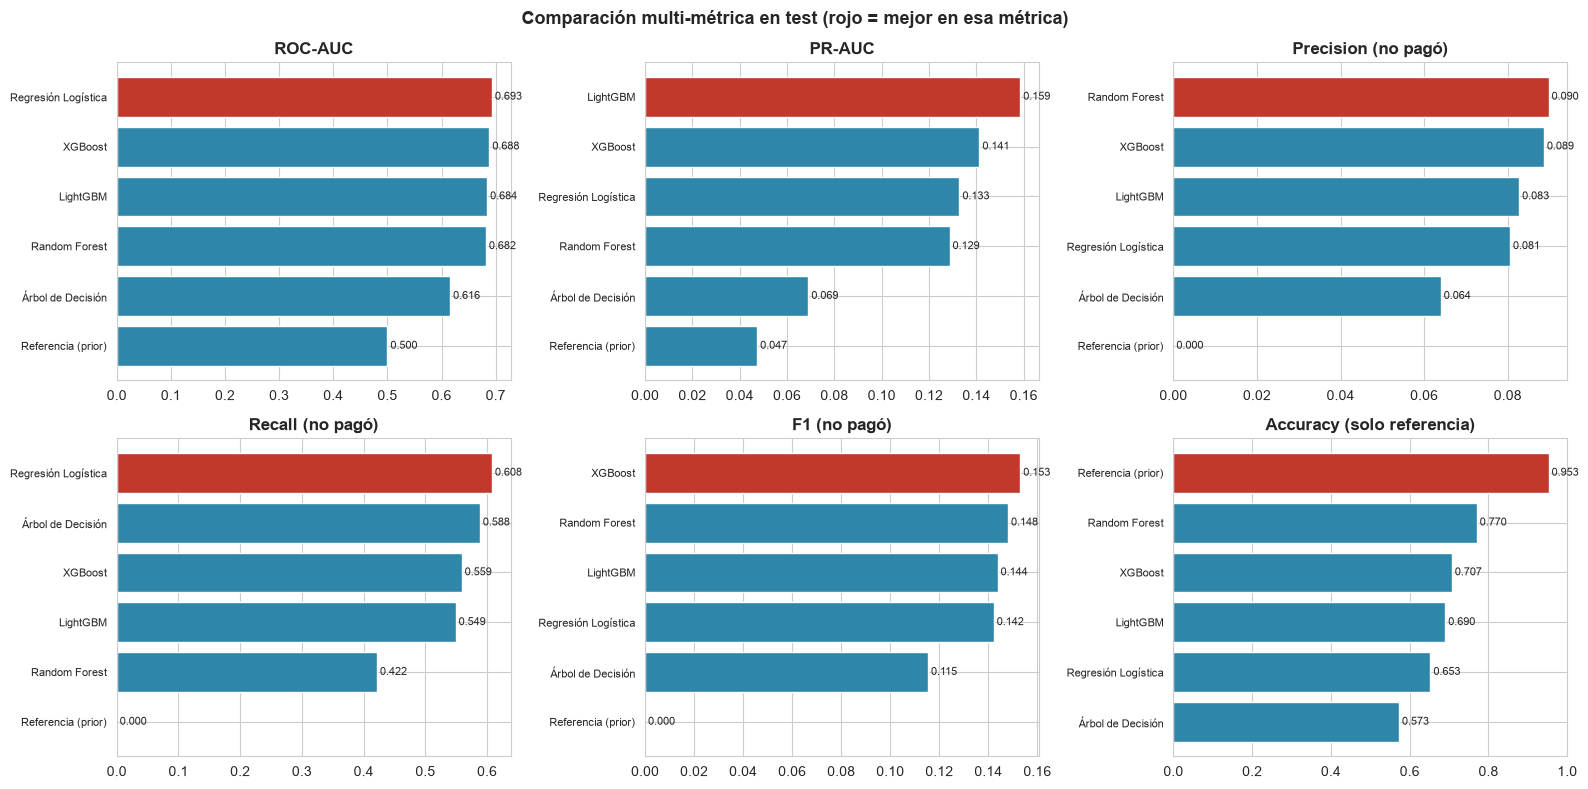

In [15]:
fig = graficar_comparacion(tabla_test, 'Comparación multi-métrica en test (rojo = mejor en esa métrica)')
plt.show()

**Interpretación.**

- **Ningún modelo gana en todas las métricas**: ROC-AUC y Recall, Regresión Logística; PR-AUC, LightGBM; Precision, Random Forest; F1, XGBoost. Con diferencias de centésimas entre los mejores, el orden cambia según la métrica y el conjunto de datos usado.
- Respecto del azar (PR-AUC sobre la proporción de "no pagó"): LightGBM 3,3 veces, XGBoost 3,0, Regresión Logística 2,8, Random Forest 2,7 y Árbol de Decisión 1,5.
- El resultado es **modesto pero consistente con una base sintética de baja calidad**, como advirtió la cátedra. No se fuerza: se documenta.

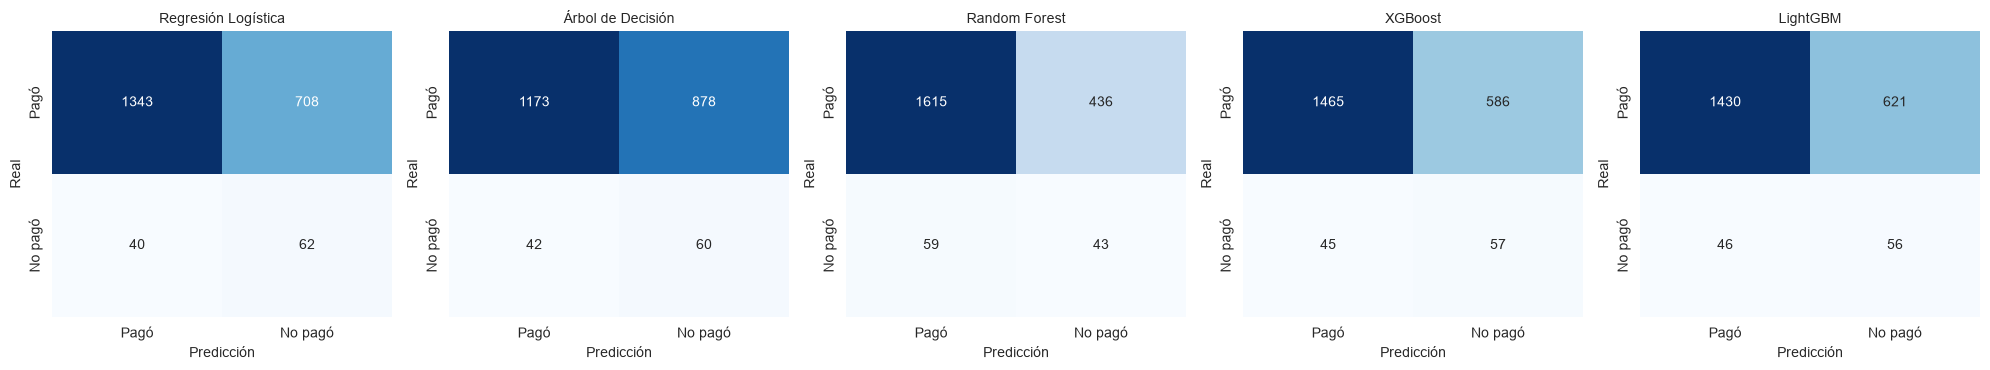

In [16]:
# Matrices de confusión de todos los modelos candidatos (umbral 0,5)
nombres = [n for n in proba_test if not n.startswith('Referencia')]
fig, ejes = plt.subplots(1, len(nombres), figsize=(4 * len(nombres), 3.8))
for eje, nombre in zip(ejes, nombres):
    prediccion = (proba_test[nombre] >= 0.5).astype(int)          # 1 = predice "no pagó"
    cm = confusion_matrix(es_no_pago_test, prediccion)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=eje,
                xticklabels=['Pagó', 'No pagó'], yticklabels=['Pagó', 'No pagó'])
    eje.set_title(nombre, fontsize=10)
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Real')
plt.tight_layout()
plt.show()

**Interpretación (umbral 0,5; filas = valor real, columnas = predicción).**

- Todos los modelos generan **muchas más falsas alarmas que aciertos**. LightGBM, por ejemplo, detecta 56 de los 102 no pagos pero marca además a 621 créditos que sí pagaron: unas 11 falsas alarmas por cada no pago detectado.
- Los modelos se distinguen por el punto del balance que eligen. La regresión logística es la más "sensible" (detecta 62 casos, con 708 falsas alarmas) y Random Forest la más "conservadora" (43 casos, con 436 falsas alarmas).
- Ese balance no es una propiedad fija del modelo sino del **umbral**: se ajusta en la sección siguiente.

<a id="14"></a>
## 14. Selección del modelo final y del umbral de decisión

**Criterio de selección:** mayor **PR-AUC medio en validación cruzada** entre los modelos sin `puntaje` (se excluye la referencia). Se usa la validación cruzada y no el test porque el test tiene ~100 no pagos: elegir con él mezclaría selección y evaluación final.

**Umbral:** con el 0,5 por defecto el modelo marca como riesgosos a muchos más créditos de los necesarios. El umbral se elige maximizando el **F1 de la clase "no pagó"** con predicciones *out-of-fold* sobre train (cada fila se predice con un modelo que no la vio), de modo que el test no interviene.

*Nota de negocio:* sin una matriz de costos real (cuánto cuesta aprobar un crédito que no se paga frente a rechazar uno que sí se pagaría), F1 es un criterio neutral. Con esos costos el umbral podría elegirse para minimizar la pérdida esperada. Se registra como mejora posible.

In [17]:
nombre_final = elegir_modelo(tabla_cv)
pipe_final = resultado['pipelines'][nombre_final]
print(f'Modelo elegido por PR-AUC medio en validación cruzada: {nombre_final}')

umbral, f1_oof = umbral_optimo_f1(pipe_final, X_train, y_train)
print(f'Umbral óptimo (F1 out-of-fold en train = {f1_oof:.4f}): {umbral:.4f}')

Modelo elegido por PR-AUC medio en validación cruzada: LightGBM
Umbral óptimo (F1 out-of-fold en train = 0.1949): 0.6009


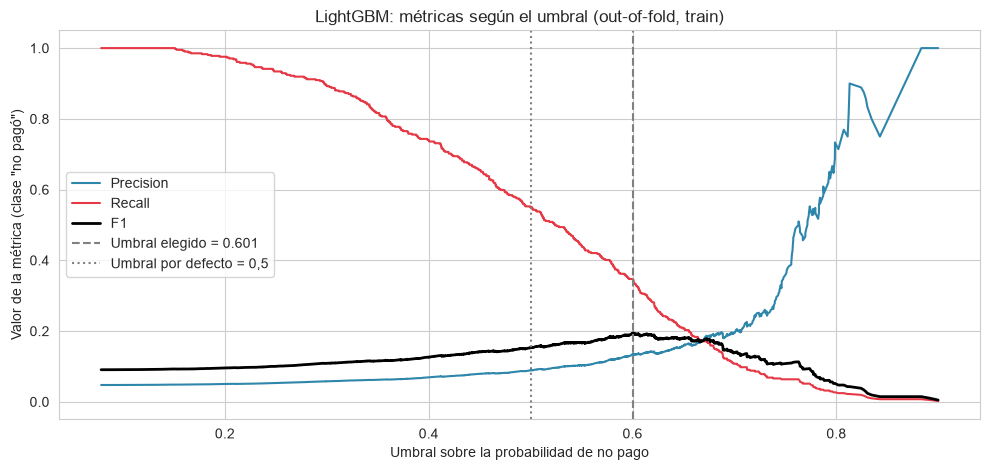

In [18]:
# Curvas Precision / Recall / F1 según el umbral (predicciones out-of-fold en train)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
oof = cross_val_predict(pipe_final, X_train, y_train, cv=cv5, method='predict_proba')
p_oof = oof[:, list(pipe_final.classes_).index(0)]
es_no_pago_train = (y_train == 0).astype(int)

precision, recall, umbrales = precision_recall_curve(es_no_pago_train, p_oof)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(umbrales, precision[:-1], label='Precision', color=COLOR_PAGO)
ax.plot(umbrales, recall[:-1], label='Recall', color=COLOR_NO_PAGO)
ax.plot(umbrales, f1, label='F1', color='black', lw=2)
ax.axvline(umbral, ls='--', color='gray', label=f'Umbral elegido = {umbral:.3f}')
ax.axvline(0.5, ls=':', color='gray', label='Umbral por defecto = 0,5')
ax.set_xlabel('Umbral sobre la probabilidad de no pago')
ax.set_ylabel('Valor de la métrica (clase "no pagó")')
ax.set_title(f'{nombre_final}: métricas según el umbral (out-of-fold, train)')
ax.legend()
plt.tight_layout()
plt.show()

,precision,recall,f1,roc_auc,pr_auc,no_pago_predichos,no_pago_reales
"umbral 0,5",0.0827,0.5490,0.1438,0.6842,0.1586,677.0000,102.0000
umbral 0.601 (elegido),0.1111,0.2843,0.1598,0.6842,0.1586,261.0000,102.0000



ROC-AUC en test: 0.684  IC 95 % bootstrap [0.620 ; 0.737]
PR-AUC  en test: 0.159  IC 95 % bootstrap [0.101 ; 0.229]


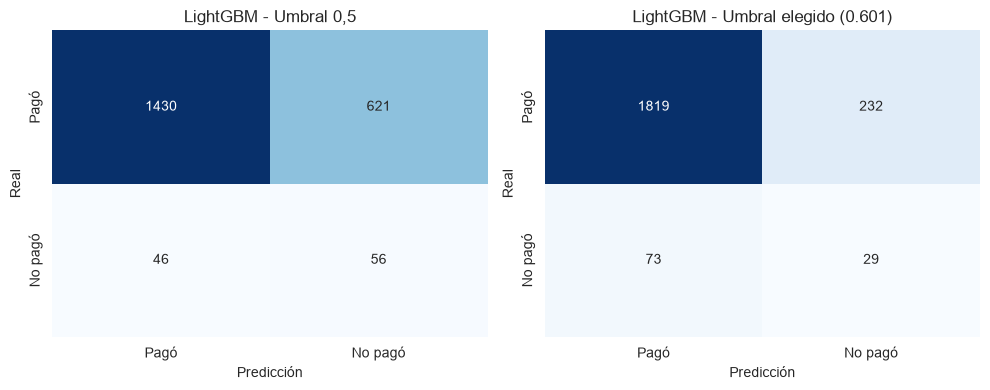

In [19]:
# Evaluación final en test: umbral por defecto frente a umbral elegido
p_test_final = proba_no_pago(pipe_final, X_test)
comparacion_umbral = pd.DataFrame({
    'umbral 0,5': calcular_metricas(y_test, p_test_final, 0.5),
    f'umbral {umbral:.3f} (elegido)': calcular_metricas(y_test, p_test_final, umbral),
}).T
display(comparacion_umbral[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'no_pago_predichos', 'no_pago_reales']])

# Intervalo de confianza bootstrap (500 remuestreos del test) para dimensionar la incertidumbre
rng = np.random.default_rng(SEMILLA)
y_arr = es_no_pago_test.to_numpy()
aucs, praucs = [], []
from sklearn.metrics import average_precision_score, roc_auc_score
for _ in range(500):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:
        continue
    aucs.append(roc_auc_score(y_arr[idx], p_test_final[idx]))
    praucs.append(average_precision_score(y_arr[idx], p_test_final[idx]))
print(f'\nROC-AUC en test: {roc_auc_score(y_arr, p_test_final):.3f}  IC 95 % bootstrap [{np.percentile(aucs, 2.5):.3f} ; {np.percentile(aucs, 97.5):.3f}]')
print(f'PR-AUC  en test: {average_precision_score(y_arr, p_test_final):.3f}  IC 95 % bootstrap [{np.percentile(praucs, 2.5):.3f} ; {np.percentile(praucs, 97.5):.3f}]')

# Matrices de confusión con ambos umbrales
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, u, titulo in zip(ejes, [0.5, umbral], ['Umbral 0,5', f'Umbral elegido ({umbral:.3f})']):
    cm = confusion_matrix(es_no_pago_test, (p_test_final >= u).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=eje,
                xticklabels=['Pagó', 'No pagó'], yticklabels=['Pagó', 'No pagó'])
    eje.set_title(f'{nombre_final} - {titulo}')
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Real')
plt.tight_layout()
plt.show()

In [20]:
# Captura por tramo de riesgo: si se revisa primero el X % de créditos con mayor probabilidad de no pago,
# ¿qué porcentaje de los no pagos reales queda dentro? (el azar capturaría exactamente el X %)
orden = np.argsort(-p_test_final)
filas = []
for porcentaje in (5, 10, 20, 30):
    k = int(len(orden) * porcentaje / 100)
    capturados = int(y_arr[orden[:k]].sum())
    filas.append({'% de créditos revisados': porcentaje, 'créditos': k, 'no pagos capturados': capturados,
                  '% de los no pagos': capturados / y_arr.sum() * 100,
                  'tasa de no pago en el tramo (%)': y_arr[orden[:k]].mean() * 100})
display(pd.DataFrame(filas).set_index('% de créditos revisados'))

,créditos,no pagos capturados,% de los no pagos,tasa de no pago en el tramo (%)
% de créditos revisados,,,,
5,107,18,17.6471,16.8224
10,215,27,26.4706,12.5581
20,430,40,39.2157,9.3023
30,645,54,52.9412,8.3721


**Interpretación.**

- **Modelo elegido: LightGBM** (PR-AUC medio de CV 0,152, ROC-AUC 0,686). La regla se aplicó de forma mecánica: la ventaja sobre XGBoost (0,146) y Random Forest (0,148) es de menos de un desvío, es decir, un empate técnico. LightGBM tiene además una brecha train/test moderada, entrena en menos de un segundo y se serializa en 48 KB.
- **Umbral 0,601** (F1 out-of-fold de 0,195). En test:
  - con 0,5 se revisaría el 31 % de los créditos (677) y se detectaría el 55 % de los no pagos (Precision 0,083);
  - con 0,601 se revisaría el 12 % (261) y se detectaría el 28 % (29 de 102; Precision 0,111, F1 0,160).

  La curva de F1 es casi plana entre 0,45 y 0,70 (aproximadamente 0,15 a 0,19), por lo que el valor exacto del umbral cambia poco el F1 y sí cambia mucho cuántos créditos se revisan.

  Qué punto conviene es una decisión de negocio: depende de cuánto cuesta revisar una solicitud frente a aprobar un crédito que no se paga. Sin esa matriz de costos, F1 es un criterio neutral.
- **Incertidumbre.** Los intervalos de confianza bootstrap (95 %) del test son amplios: ROC-AUC 0,684 [0,620 ; 0,737] y PR-AUC 0,159 [0,101 ; 0,229]. Las diferencias entre modelos de la sección 13 (≤ 0,02) quedan dentro de esos intervalos.
- **Captura por tramo de riesgo.** El 10 % de los créditos con mayor probabilidad de no pago concentra el 26,5 % de los no pagos (27 de 102; tasa de no pago de 12,6 % frente a 4,7 % del total), y el 30 % concentra el 52,9 %. Es la lectura más útil para el negocio: priorizar la revisión manual de los tramos de mayor riesgo.

<a id="15"></a>
## 15. Control con partición temporal

El EDA mostró que la cartera cambió con el tiempo (sección 10). Una partición aleatoria mezcla períodos y puede ser optimista. Como control se repite el entrenamiento **entrenando con el 80 % más antiguo y probando con el 20 % más reciente**, que es lo que ocurriría en producción (predecir créditos nuevos con un modelo entrenado con el pasado). Es solo un control: la partición oficial del proyecto sigue siendo la estratificada.

In [21]:
datos_temp = ft_engineering(df, con_puntaje=False, temporal=True)
resultado_temp = comparar_modelos(datos_temp, con_puntaje=False, con_cv=False)

print('PARTICIÓN TEMPORAL')
print('=' * 70)
print(f'Train: {datos_temp["X_train"].shape[0]:,} créditos | % no pagaron: {(datos_temp["y_train"] == 0).mean() * 100:.2f}')
print(f'Test : {datos_temp["X_test"].shape[0]:,} créditos | % no pagaron: {(datos_temp["y_test"] == 0).mean() * 100:.2f} '
      f'({(datos_temp["y_test"] == 0).sum()} casos)')

comp_temporal = pd.DataFrame({
    'ROC-AUC (aleatoria)': test_sin['roc_auc'],
    'ROC-AUC (temporal)': resultado_temp['metricas'].query("conjunto == 'test'").set_index('modelo')['roc_auc'],
    'PR-AUC (aleatoria)': test_sin['pr_auc'],
    'PR-AUC (temporal)': resultado_temp['metricas'].query("conjunto == 'test'").set_index('modelo')['pr_auc'],
})
display(comp_temporal)

PARTICIÓN TEMPORAL
Train: 8,610 créditos | % no pagaron: 5.13
Test : 2,153 créditos | % no pagaron: 3.20 (69 casos)


,ROC-AUC (aleatoria),ROC-AUC (temporal),PR-AUC (aleatoria),PR-AUC (temporal)
modelo,,,,
Referencia (prior),0.5000,0.5000,0.0474,0.0320
Regresión Logística,0.6931,0.6312,0.1328,0.0936
Árbol de Decisión,0.6158,0.5823,0.0690,0.0499
Random Forest,0.6819,0.6530,0.1287,0.0658
XGBoost,0.6884,0.6570,0.1413,0.0729
LightGBM,0.6842,0.6573,0.1586,0.0878


**Interpretación.**

- Con la partición temporal el rendimiento **baja en todos los modelos**: el ROC-AUC de los cuatro mejores pasa de 0,68-0,69 a 0,63-0,66 y el PR-AUC de LightGBM de 0,159 a 0,088. Es la estimación más realista de lo que ocurriría con créditos nuevos.
- Aun así, los modelos siguen por encima de la referencia (PR-AUC 0,032): LightGBM rinde 2,7 veces el azar frente a 3,3 en la partición aleatoria. LightGBM tiene el mayor ROC-AUC en este control (0,657) y la regresión logística el mayor PR-AUC (0,094); el ranking entre los cuatro mejores vuelve a ser un empate técnico.
- El último 20 % de la cartera tiene una **tasa de no pago de 3,20 %** (69 casos) frente a 5,13 % en el 80 % anterior. Una explicación posible, que la base no permite confirmar, es que los créditos más recientes aún no tuvieron tiempo de caer en mora. Esto refuerza la necesidad de monitorear el cambio de la cartera (*data drift*, Avance 3).
- Conclusión: la degradación es moderada y no cambia la elección. Se mantiene la partición estratificada como oficial y se documenta este control.

<a id="16"></a>
## 16. Variables que explican el riesgo

Dos lecturas complementarias: la **importancia por ganancia** del modelo elegido (cuánto aporta cada variable a reducir el error, sin indicar la dirección) y los **coeficientes de la regresión logística** (con dirección: positivo = mayor riesgo de no pago; las variables están estandarizadas y los montos en logaritmo, por lo que son comparables entre sí).

Par colineal (se compensa): {'tendencia_ingresos_Sin dato': -1.771, 'missingindicator_promedio_ingresos_datacredito': 1.135} | suma = -0.637

Coeficientes mostrados:
tendencia_ingresos_Decreciente          0.6820
tipo_credito_6                          0.6430
tendencia_ingresos_Estable              0.5740
cuota_pactada                           0.5510
tendencia_ingresos_Creciente            0.4500
plazo_meses                             0.4240
missingindicator_puntaje_datacredito    0.3780
huella_consulta                         0.3450
tipo_credito_10                        -0.2420
puntaje_datacredito                    -0.2460
capital_prestado                       -0.3550
tipo_credito_Otros                     -0.6420

Importancia por ganancia (top 8, %):
puntaje_datacredito             20.3000
huella_consulta                 10.6000
promedio_ingresos_datacredito    9.1000
plazo_meses                      8.7000
capital_prestado                 7.4000
edad_cliente                    

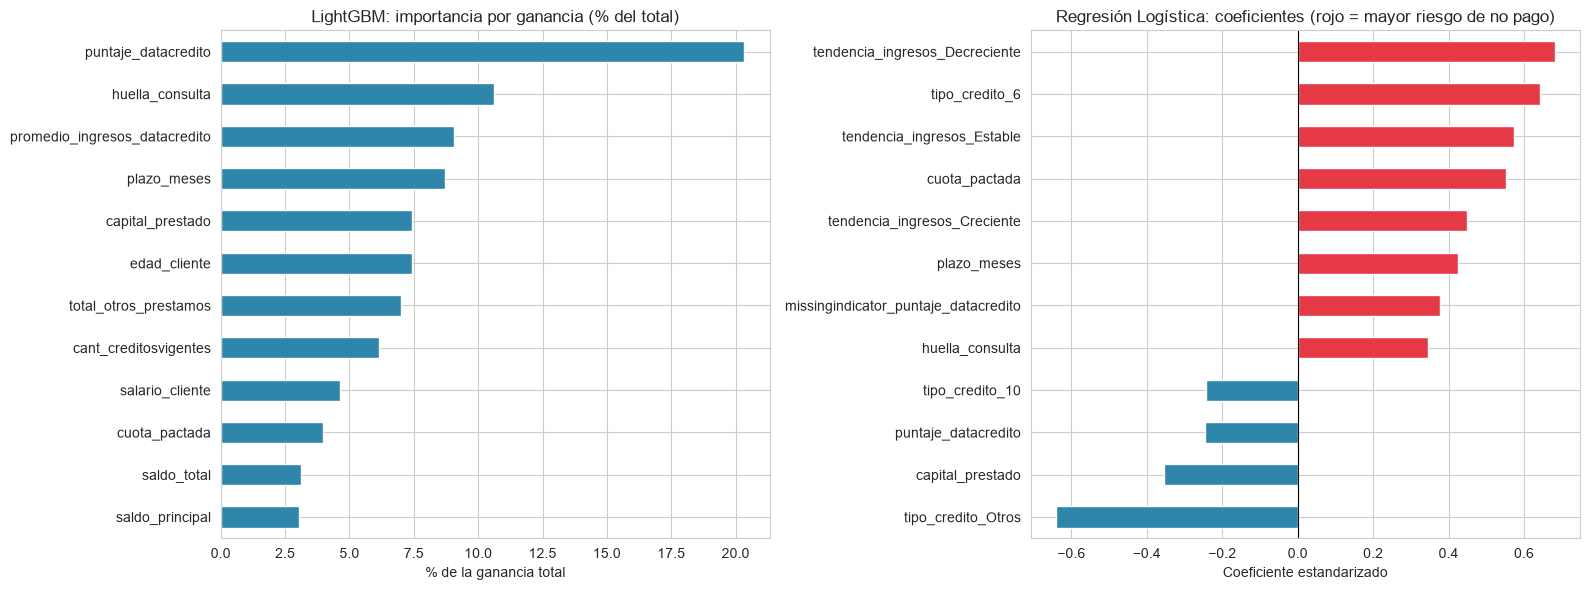

In [22]:
# 1) Importancia por ganancia del modelo final (LightGBM)
nombres_features = pipe_final['features']['preprocesador'].get_feature_names_out()
importancia = pd.Series(pipe_final['modelo'].booster_.feature_importance(importance_type='gain'),
                        index=nombres_features).sort_values(ascending=False)
importancia = importancia / importancia.sum() * 100

# 2) Coeficientes de la regresión logística. Se invierte el signo para que
#    positivo = mayor riesgo de NO pago (el modelo predice la clase 1 = pagó).
pipe_lr = resultado['pipelines']['Regresión Logística']
coef = pd.Series(-pipe_lr['modelo'].coef_[0], index=pipe_lr['features']['preprocesador'].get_feature_names_out())

# Dos columnas describen casi las mismas filas ('Sin dato' en tendencia_ingresos y el indicador de faltante
# de promedio_ingresos_datacredito): sus coeficientes se compensan y no se leen por separado.
colineales = ['tendencia_ingresos_Sin dato', 'missingindicator_promedio_ingresos_datacredito']
print('Par colineal (se compensa):', coef[colineales].round(3).to_dict(), '| suma =', round(coef[colineales].sum(), 3))
coef = coef.drop(colineales)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).sort_values()
print('\nCoeficientes mostrados:')
print(top_coef.sort_values(ascending=False).round(3).to_string())
print('\nImportancia por ganancia (top 8, %):')
print(importancia.head(8).round(1).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
importancia.head(12).sort_values().plot(kind='barh', color=COLOR_PAGO, ax=ejes[0])
ejes[0].set_title(f'{nombre_final}: importancia por ganancia (% del total)')
ejes[0].set_xlabel('% de la ganancia total')
colores = [COLOR_NO_PAGO if v > 0 else COLOR_PAGO for v in top_coef.values]
top_coef.plot(kind='barh', color=colores, ax=ejes[1])
ejes[1].axvline(0, color='black', lw=0.8)
ejes[1].set_title('Regresión Logística: coeficientes (rojo = mayor riesgo de no pago)')
ejes[1].set_xlabel('Coeficiente estandarizado')
plt.tight_layout()
plt.show()

**Interpretación.**

- **LightGBM (ganancia).** `puntaje_datacredito` es la variable más usada (20,3 % de la ganancia total), seguida de `huella_consulta` (10,6 %), `promedio_ingresos_datacredito` (9,1 %), `plazo_meses` (8,7 %), `capital_prestado` y `edad_cliente` (7,4 % cada una). Coincide en gran parte con el EDA, donde `puntaje_datacredito` (AUC individual 0,623), `huella_consulta` (0,598), `edad_cliente` (0,574), `capital_prestado` (0,557) y `promedio_ingresos_datacredito` (0,548) eran las cinco con mejor AUC individual; `plazo_meses` es la única de las seis primeras que no estaba en esa lista. La importancia está repartida: no hay una variable que explique el riesgo por sí sola.
- **Regresión logística (dirección del efecto; positivo = mayor riesgo de no pago).** Un puntaje externo mayor reduce el riesgo (−0,25); más consultas crediticias (+0,35), cuotas más altas (+0,55), plazos más largos (+0,42) y el producto 6 (+0,64) lo aumentan. Dentro de `tendencia_ingresos` el orden Decreciente (+0,68) > Estable (+0,57) > Creciente (+0,45) coincide con el EDA; los tres son positivos porque se miden contra la categoría "Sin dato", por eso solo se comparan entre sí. `capital_prestado` (−0,36) y `cuota_pactada` (+0,55) tienen signos opuestos porque están correlacionados (0,75): conviene leerlos juntos, como "cuota alta en relación con el monto".
- **Par colineal.** El coeficiente de "Sin dato" en `tendencia_ingresos` (−1,77) y el del indicador de falta de `promedio_ingresos_datacredito` (+1,14) describen casi las mismas filas y se compensan entre sí (suma −0,64); por eso se excluyeron del gráfico. Los coeficientes de `tipo_credito_Otros` (n = 3) y `tipo_credito_6` (n = 21) se apoyan en muy pocos créditos y no son concluyentes.

<a id="17"></a>
## 17. Guardado y verificación del modelo

Se guarda un único archivo `modelo_final.joblib` con el *pipeline* ajustado (limpieza + preprocesado + modelo), el umbral y la metadata. La API del Avance 4 lo cargará y recibirá los datos **crudos**, sin repetir ninguna transformación a mano.

Se verifica que el archivo guardado reproduzca exactamente las predicciones del modelo en memoria y que acepte una fila con valores problemáticos (edad imposible, código de crédito nuevo, tendencia inválida).

In [23]:
import joblib
from model_training_evaluation import RUTA_MODELO

metricas_test_final = calcular_metricas(y_test, p_test_final, umbral)
ruta = guardar_modelo(pipe_final, umbral, nombre_final, metricas_test_final)
print(f'Guardado: {ruta.name} ({ruta.stat().st_size / 1024:,.0f} KB)')

# --- Verificación 1: el archivo reproduce las predicciones del modelo en memoria ---
paquete = joblib.load(RUTA_MODELO)
p_cargado = proba_no_pago(paquete['pipeline'], X_test)
print('Predicciones idénticas tras recargar:', np.allclose(p_cargado, p_test_final))
print(f'Contenido del paquete: {list(paquete.keys())}')

# --- Verificación 2: una fila "sucia", tal como podría llegar a la API ---
fila = X_test.iloc[[0]].copy()
fila['edad_cliente'] = 122                 # edad imposible
fila['tipo_credito'] = '5'                 # código de producto nunca visto
fila['tendencia_ingresos'] = '7'           # categoría inválida
p = proba_no_pago(paquete['pipeline'], fila)[0]
print(f'\nFila con datos problemáticos -> probabilidad de no pago: {p:.4f} '
      f'({"NO PAGA" if p >= paquete["umbral_no_pago"] else "PAGA"} con umbral {paquete["umbral_no_pago"]:.3f})')
print('Columnas de entrada que espera la API:', paquete['columnas_entrada'])

Guardado: modelo_final.joblib (48 KB)
Predicciones idénticas tras recargar: True
Contenido del paquete: ['pipeline', 'umbral_no_pago', 'nombre_modelo', 'columnas_entrada', 'metricas_test', 'semilla']

Fila con datos problemáticos -> probabilidad de no pago: 0.3453 (PAGA con umbral 0.601)
Columnas de entrada que espera la API: ['capital_prestado', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'saldo_mora', 'saldo_total', 'saldo_principal', 'saldo_mora_codeudor', 'promedio_ingresos_datacredito', 'plazo_meses', 'edad_cliente', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'tipo_credito', 'tipo_laboral', 'tendencia_ingresos']


**Verificación.** El archivo reproduce exactamente las predicciones del modelo en memoria, y el pipeline procesa sin error una fila con una edad imposible (122), un código de crédito nunca visto ("5") y una tendencia de ingresos inválida ("7"): la limpieza y el preprocesador están dentro del pipeline, por lo que la API podrá recibir los datos tal como llegan.

Observaciones para el despliegue (Avance 4):

- El archivo se guarda en `mlops_pipeline/src/` porque la estructura obligatoria no prevé una carpeta para artefactos. Se consultará con el equipo si se prefiere otra ubicación.
- Al cargar el `.joblib`, `ft_engineering.py` debe poder importarse (mismo directorio o `PYTHONPATH`): el pipeline referencia sus funciones de limpieza.
- Para evitar incompatibilidades entre versiones, el archivo debe generarse con las mismas versiones de scikit-learn y LightGBM que usará la API (se fijarán en `requirements.txt`).

<a id="18"></a>
## 18. Conclusiones, limitaciones y próximos pasos

### 18.1 Resumen del avance

- Se implementó `ft_engineering.py`: limpieza por reglas, imputación con indicadores de faltante, transformación logarítmica y escalado (solo modelos lineales) y codificación One-Hot, todo dentro de un *pipeline* que se ajusta únicamente con entrenamiento.
- Se entrenaron y compararon cinco modelos más una referencia, con partición estratificada (semilla 42) y validación cruzada de 5 folds, sobre las métricas de la clase "no pagó".
- Se documentó el efecto de `puntaje`: con esa variable todos los modelos alcanzan ROC-AUC = 1,000 (fuga de información); sin ella, entre 0,62 y 0,69. El modelo de producción **no la usa**.
- **Modelo elegido: LightGBM** (ROC-AUC 0,684 y PR-AUC 0,159 en test; 0,686 y 0,152 en validación cruzada), con umbral 0,601. Guardado en `modelo_final.joblib` como un único *pipeline* de datos crudos a probabilidad.
- Resultado práctico: revisando el 10 % de las solicitudes de mayor riesgo se alcanzaría el 26,5 % de los no pagos.

### 18.2 Limitaciones

| Limitación | Causa | Cómo se aborda |
|---|---|---|
| Señal predictiva débil (ROC-AUC ≈ 0,68) | Base sintética y de baja calidad, sin diccionario de variables | Se documentan las métricas sin forzarlas; el modelo sirve para priorizar, no para decidir solo |
| Métricas de test inestables | Solo 102 no pagos en test (IC 95 % del ROC-AUC: 0,62 a 0,74) | Validación cruzada, intervalos bootstrap y no declarar ganadores por diferencias menores a un desvío |
| Elección entre cuatro modelos casi empatados | Diferencias menores al desvío entre folds | Criterio explícito (PR-AUC de CV); se valoró además el sobreajuste, el tamaño y la velocidad |
| Menor rendimiento con partición temporal | La cartera cambió en el tiempo; los créditos recientes pueden estar subestimando el no pago | Control temporal documentado; monitoreo de *data drift* en el Avance 3 |
| Muchas falsas alarmas (Precision 0,08 a 0,11) | Señal débil y clase minoritaria | Umbral por F1; la elección definitiva requiere costos reales del negocio |
| `puntaje` excluido | Fuga de información probable | Pendiente confirmar con el equipo si existe al otorgar el crédito |
| Hiperparámetros no optimizados formalmente | El rendimiento es insensible al ajuste (sección 9) | Configuración conservadora; Grid Search u Optuna como mejora futura |
| Imputación por mediana | Los saldos con nulos podrían ser ceros reales | Indicadores de faltante para conservar la información |

### 18.3 Supuestos y limitaciones

- **`puntaje` excluida del modelo final:** se asumió que no está disponible al momento de otorgar el crédito. Con ella todos los modelos llegan a ROC-AUC = 1,000, señal de fuga de información. Si el negocio confirmara que sí se conoce en ese momento, habría que revisar esta decisión.
- **Umbral de decisión:** se eligió el que maximiza el F1 de la clase "no pagó" (0,601). Una decisión real requeriría una matriz de costos (cuánto cuesta aprobar un crédito que no se paga frente a rechazar uno que sí se pagaría).
- **Base sintética y poca señal:** el mejor modelo llega a ROC-AUC ≈ 0,68 y hay solo 102 casos de no pago en el conjunto de prueba, por lo que las métricas son inestables. Se documentan sin forzarlas.
- **Modelo guardado:** `models/modelo_final.joblib` (pipeline completo, umbral y lista de las 20 columnas de entrada), listo para ser consumido por la API.